# Percptron


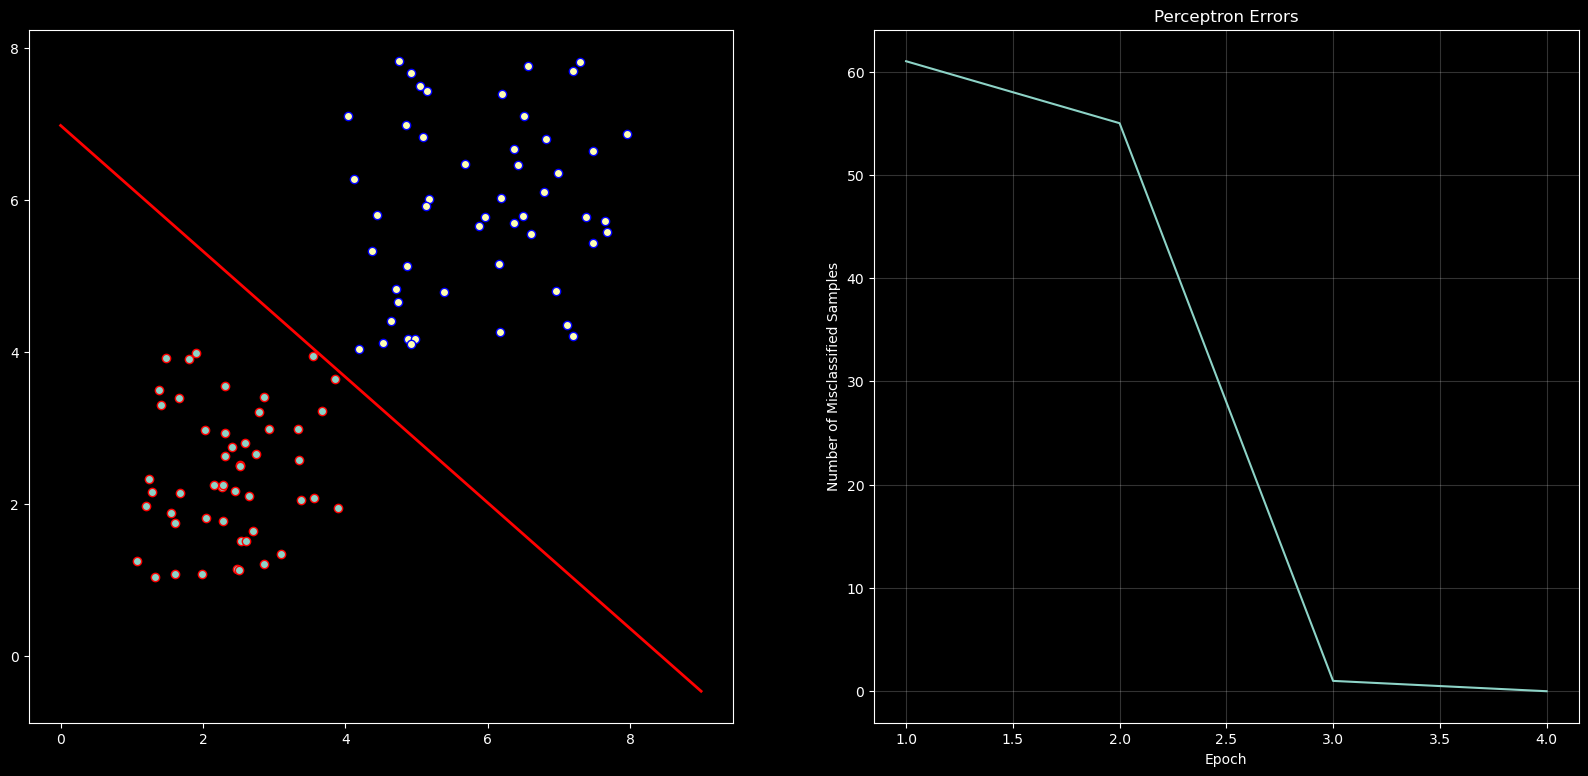

In [6]:
import numpy as np 
import matplotlib.pyplot as plt 

plt.style.use('dark_background')

# Prepar data
np.random.seed(2)
n_sample = 50

cats_x1 = np.random.uniform (1,4,n_sample) 
cats_x2 =np.random.uniform (1,4,n_sample) 
cats = np.column_stack([cats_x1,cats_x2])
cats_label = -np.ones(n_sample)


dags_x1 = np.random.uniform (4,8,n_sample) 
dogs_x2 =np.random.uniform (4,8,n_sample) 
dogs = np.column_stack([dags_x1,dogs_x2])
dogs_label = np.ones(n_sample)

x = np.vstack([cats,dogs])
y = np.concatenate([cats_label,dogs_label])

indices = np.random.permutation(len(x))
x = x[indices]
y = y[indices]

plt.figure(figsize=(20,9),dpi=100)
plt.subplot(1,2,1)
plt.scatter(cats[:,0],cats[:,1],marker="o",label="Cats(-1)",edgecolors="r")
plt.scatter(dogs[:,0],dogs[:,1],marker="o",label="Dogs(+1)",edgecolors="b")


w1 = np.random.rand(1)[0]
w2 = np.random.rand(1)[0]
b = np.random.rand(1)[0]

eta = 0.01
epochs = 1000
errors =np.zeros(epochs)


for i in range(epochs):
    error_count = 0

    for j in range(len(x)) :
        z = w1 * x[j,0] + w2 * x [j,1] + b
        yhat = 1 if z >=0 else -1 
        if yhat != y[j]:
            w1 = w1 + eta*(y[j] - yhat) * x[j,0]
            w2 = w2 +eta*(y[j] - yhat) * x[j,1]
            b = b + eta*(y[j] - yhat)
            error_count +=1
    
    errors[i]=error_count

    if error_count == 0 :
        break

x1_vals = np.linspace (0,9,100)
x2_vals =-(w1*x1_vals+b) / w2 #w1x1+w2x2+b=0

plt.xlabel("Feature 1 (x1)")
plt.ylabel("Feature 2 (x2)")
plt.xlim(0, 9)
plt.ylim(0, 9)
plt.title("Perco\ Classification")

plt.plot(x1_vals,x2_vals,'-r',linewidth =2 , label = "Decision boundary")

plt.subplot(1,2,2)
plt.plot(range(1,i+2),errors[:i+1])

plt.xlabel("Epoch")
plt.ylabel("Number of Misclassified Samples")
plt.title("Perceptron Errors")
plt.grid(alpha=0.2)


plt.show()

# Adaline Full Matrix



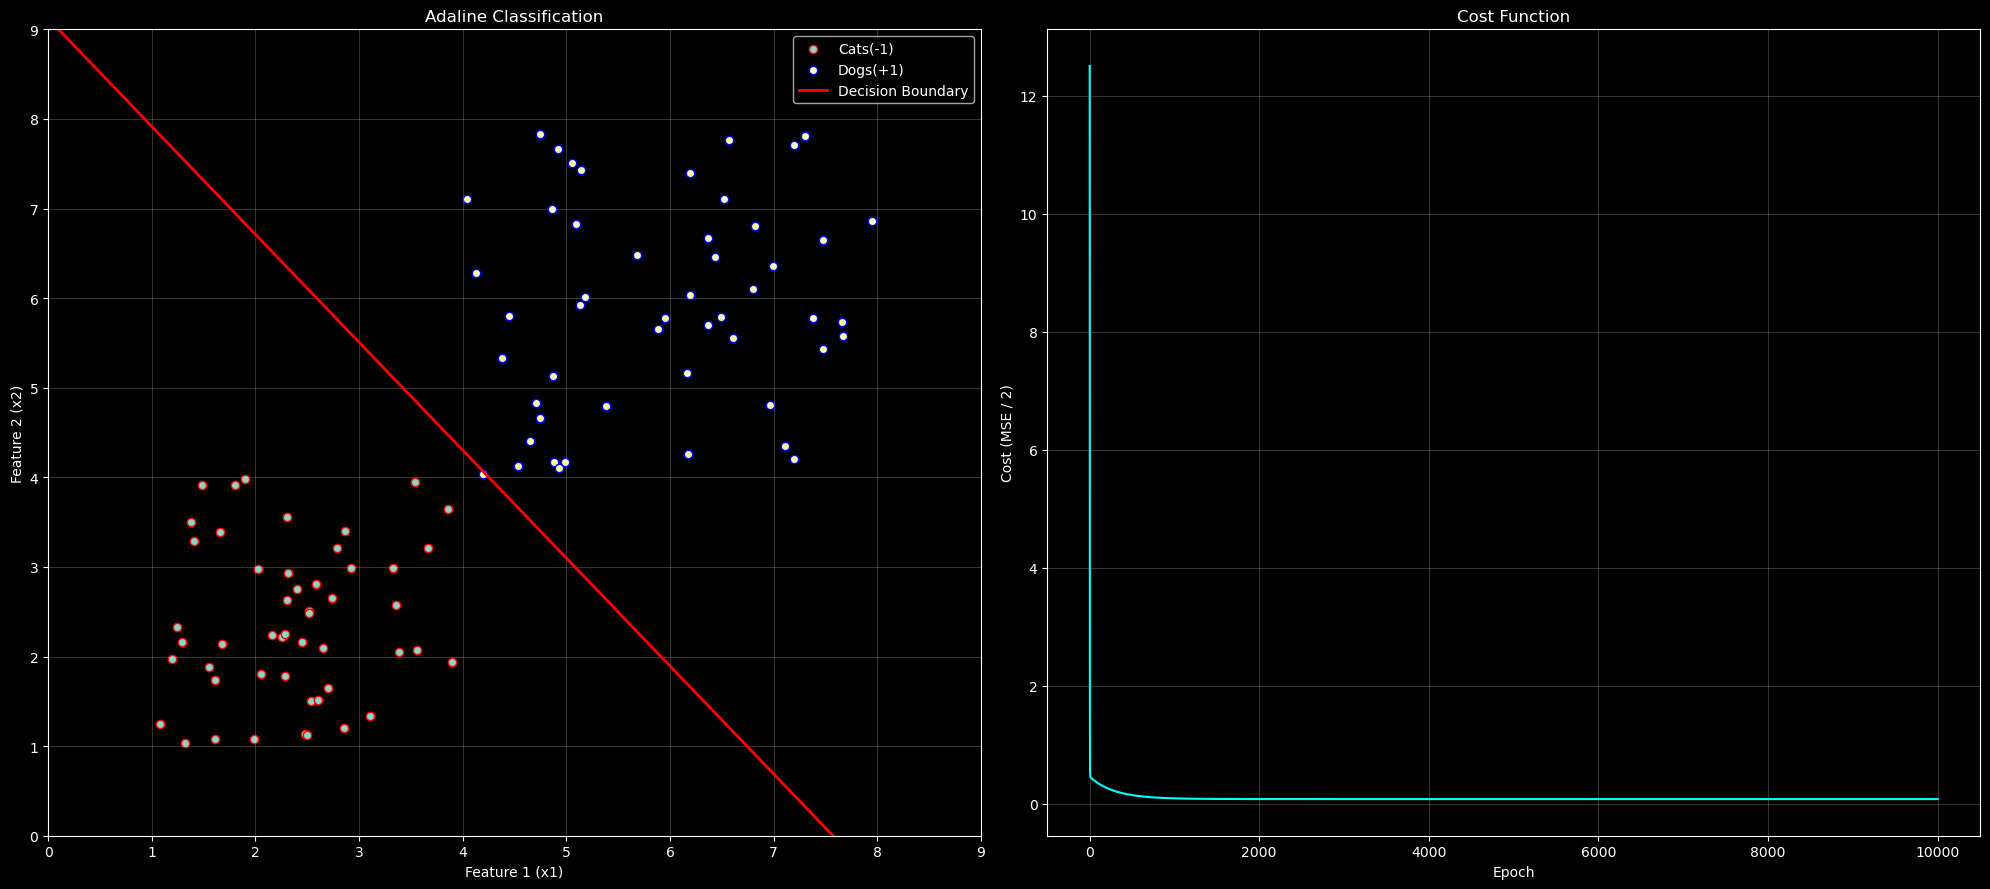

In [2]:
import numpy as np 
import matplotlib.pyplot as plt 

plt.style.use('dark_background')

# Prepar data
np.random.seed(2)
n_sample = 50

cats_x1 = np.random.uniform (1,4,n_sample) 
cats_x2 =np.random.uniform (1,4,n_sample) 
cats = np.column_stack([cats_x1,cats_x2])
cats_label = -np.ones(n_sample)


dags_x1 = np.random.uniform (4,8,n_sample) 
dogs_x2 =np.random.uniform (4,8,n_sample) 
dogs = np.column_stack([dags_x1,dogs_x2])
dogs_label = np.ones(n_sample)

x = np.vstack([cats,dogs])
y = np.concatenate([cats_label,dogs_label])

indices = np.random.permutation(len(x))
x = x[indices]
y = y[indices]

plt.figure(figsize=(20,9),dpi=100)
plt.subplot(1,2,1)
plt.scatter(cats[:,0],cats[:,1],marker="o",label="Cats(-1)",edgecolors="r")
plt.scatter(dogs[:,0],dogs[:,1],marker="o",label="Dogs(+1)",edgecolors="b")

w =np.random.rand(3)
x_bias = np.column_stack([np.ones(len(x)), x])
eta = 0.01
epochs = 10000
costVal = np.zeros(epochs)

for i in range(epochs) :
    z = x_bias @ w
    error = z - y
    w = w - eta * (x_bias.T @ error) / len(x)
    costVal [i] = 0.5 * np.mean(error**2)

    if costVal[i] <1e-5 :
        break


b= w[0]        
w1= w[1]        
w2= w[2]   

# Decision boundary: w1*x1 + w2*x2 + b = 0
x1_vals = np.linspace(0, 9, 100)
x2_vals = -(w1 * x1_vals + b) / w2

plt.plot(x1_vals, x2_vals, "-r",
         linewidth=2, label="Decision Boundary")

plt.xlabel("Feature 1 (x1)")
plt.ylabel("Feature 2 (x2)")
plt.xlim(0, 9)
plt.ylim(0, 9)
plt.title("Adaline Classification")
plt.legend()
plt.grid(alpha=0.2)

# Plot 2: Cost function
plt.subplot(1, 2, 2)

plt.plot(range(1, i + 2), costVal[:i + 1], color="cyan")

plt.xlabel("Epoch")
plt.ylabel("Cost (MSE / 2)")
plt.title("Cost Function")
plt.grid(True,alpha=0.2)

plt.tight_layout()
plt.show()
        

# Percptron full matrix 



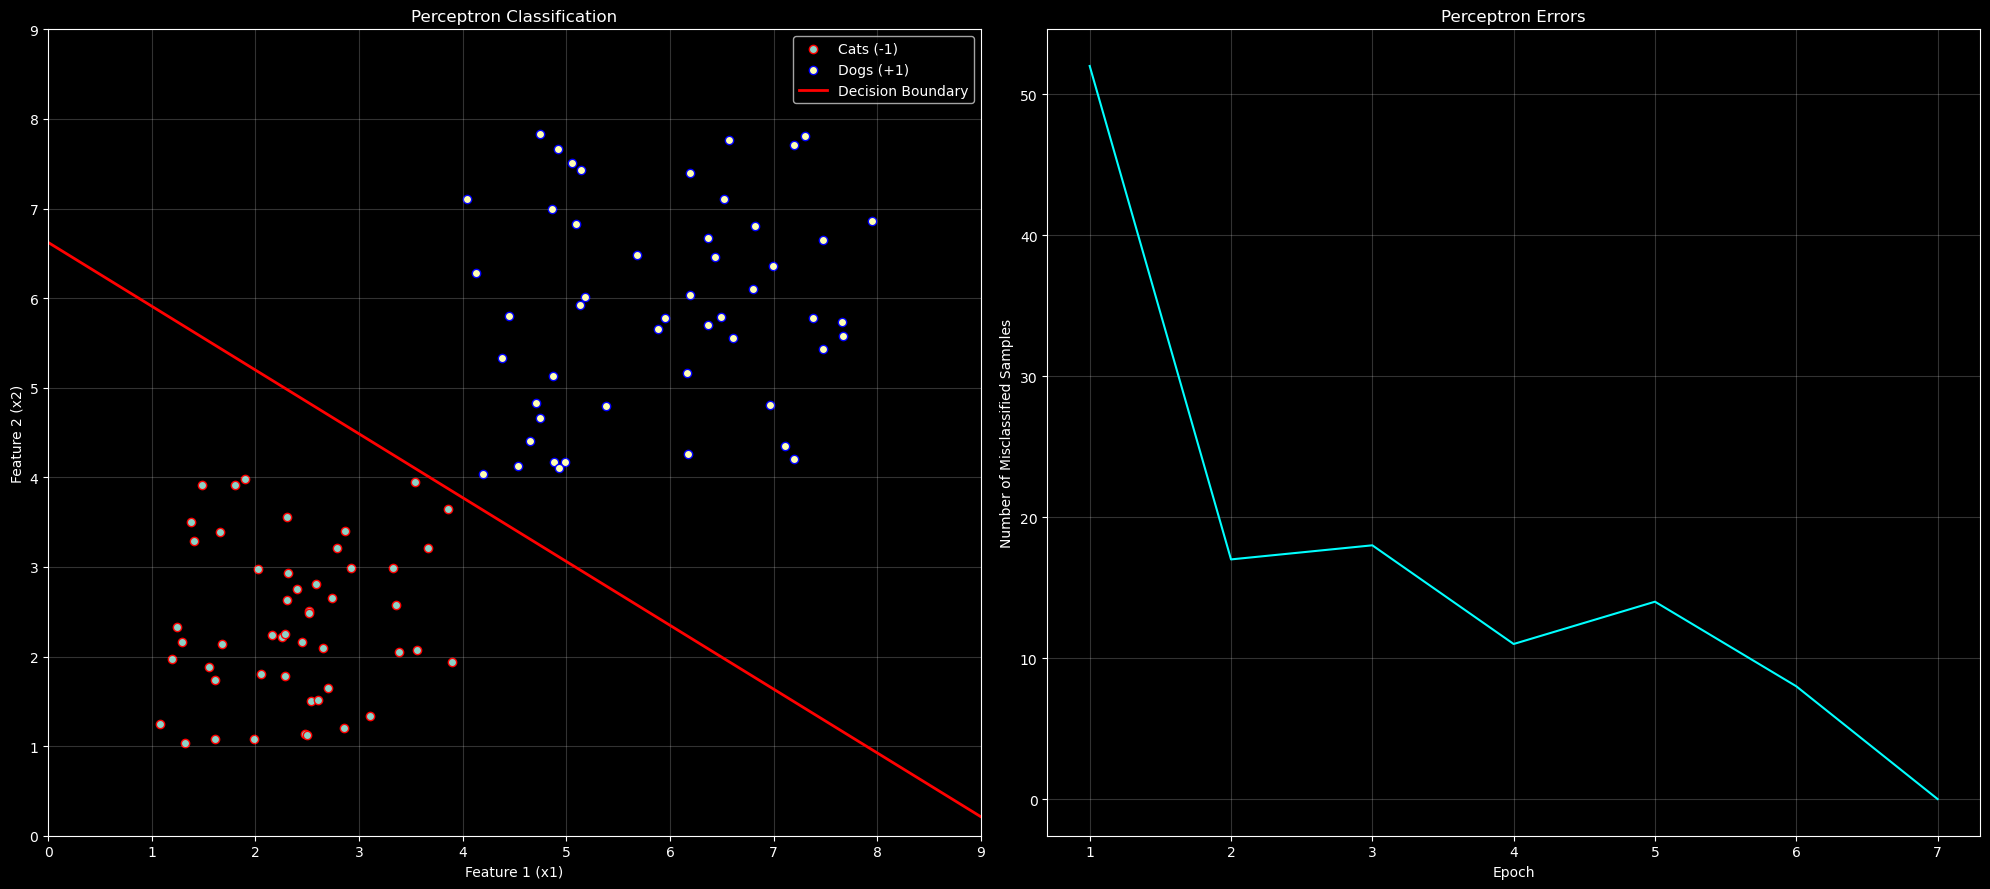

In [3]:
# Percptron full matrix 

import numpy as np
import matplotlib.pyplot as plt

plt.style.use('dark_background')

# Prepare data
np.random.seed(2)
n_sample = 50

cats_x1 = np.random.uniform(1, 4, n_sample)
cats_x2 = np.random.uniform(1, 4, n_sample)
cats = np.column_stack([cats_x1, cats_x2])
cats_label = -np.ones(n_sample)

dogs_x1 = np.random.uniform(4, 8, n_sample)
dogs_x2 = np.random.uniform(4, 8, n_sample)
dogs = np.column_stack([dogs_x1, dogs_x2])
dogs_label = np.ones(n_sample)

x = np.vstack([cats, dogs])
y = np.concatenate([cats_label, dogs_label])

# Shuffle data
indices = np.random.permutation(len(x))
x = x[indices]
y = y[indices]

# Add bias column
x_bias = np.column_stack([np.ones(len(x)), x])
w = np.random.rand(3)
# Plot data
plt.figure(figsize=(20, 9), dpi=100)
plt.subplot(1, 2, 1)

plt.scatter(cats[:, 0], cats[:, 1],marker="o", label="Cats (-1)", edgecolors="r")
plt.scatter(dogs[:, 0], dogs[:, 1],marker="o", label="Dogs (+1)", edgecolors="b")


eta = 0.01
epochs = 1000
errors = np.zeros(epochs)

# Perceptron training
for i in range(epochs):
    error_count = 0

    for j in range(len(x)):
        z = x_bias[j] @ w

        yhat = 1 if z >= 0 else -1

        if yhat != y[j]:
            w = w + eta * (y[j] - yhat) * x_bias[j]
            error_count += 1

    errors[i] = error_count

    if error_count == 0:
        break

# Extract weights and bias for plotting
b= w[0]        
w1= w[1]        
w2= w[2]  

# Decision boundary
x1_vals = np.linspace(0, 9, 100)
x2_vals = -(w1 * x1_vals + b) / w2

plt.plot(x1_vals, x2_vals, '-r',linewidth=2, label="Decision Boundary")

plt.xlabel("Feature 1 (x1)")
plt.ylabel("Feature 2 (x2)")
plt.xlim(0, 9)
plt.ylim(0, 9)
plt.title("Perceptron Classification")
plt.legend()
plt.grid(alpha=0.2)

# Plot errors
plt.subplot(1, 2, 2)
plt.plot(range(1, i + 2), errors[:i + 1], color="cyan")

plt.xlabel("Epoch")
plt.ylabel("Number of Misclassified Samples")
plt.title("Perceptron Errors")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()
